In [5]:

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from superfv.tools.stability_analysis.rk import compute_rk_amplification
from superfv.tools.stability_analysis.variables import h, nu

In [6]:
alpha = sp.Symbol("alpha", real=True)
dt_max = alpha * h**2 / nu
dt_max

alpha*h**2/nu

In [7]:
def plot_amplification_vs_cfl(ax, cfl_values, p, rk, **kwargs):
    k_values = np.linspace(0, 2 * np.pi, 100)

    max_amps = []
    for cfl in cfl_values:
        max_amp = compute_rk_amplification(p, k_values, cfl_value=cfl, rk=rk, operator="diffusion")
        max_amps.append(max_amp)

    ax.plot(cfl_values, max_amps, **kwargs)

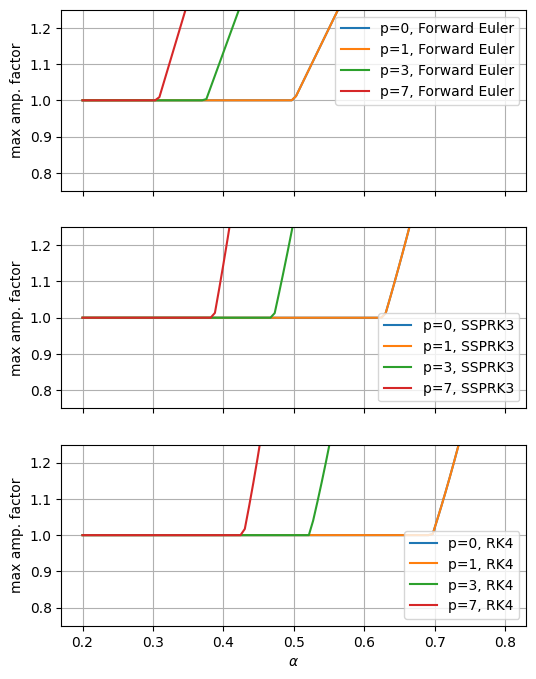

In [8]:
fig, axs = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(6, 8))
axs[2].set_xlabel(r"$\alpha$")
axs[0].set_ylim(0.75, 1.25)

cfl_values = np.linspace(0.2, 0.8, 100)

plot_amplification_vs_cfl(axs[0], cfl_values, p=0, rk="forward_euler", label="p=0, Forward Euler")
plot_amplification_vs_cfl(axs[0], cfl_values, p=1, rk="forward_euler", label="p=1, Forward Euler")
plot_amplification_vs_cfl(axs[0], cfl_values, p=3, rk="forward_euler", label="p=3, Forward Euler")
plot_amplification_vs_cfl(axs[0], cfl_values, p=7, rk="forward_euler", label="p=7, Forward Euler")



plot_amplification_vs_cfl(axs[1], cfl_values, p=0, rk="ssprk3", label="p=0, SSPRK3")
plot_amplification_vs_cfl(axs[1], cfl_values, p=1, rk="ssprk3", label="p=1, SSPRK3")
plot_amplification_vs_cfl(axs[1], cfl_values, p=3, rk="ssprk3", label="p=3, SSPRK3")
plot_amplification_vs_cfl(axs[1], cfl_values, p=7, rk="ssprk3", label="p=7, SSPRK3")

plot_amplification_vs_cfl(axs[2], cfl_values, p=0, rk="rk4", label="p=0, RK4")
plot_amplification_vs_cfl(axs[2], cfl_values, p=1, rk="rk4", label="p=1, RK4")
plot_amplification_vs_cfl(axs[2], cfl_values, p=3, rk="rk4", label="p=3, RK4")
plot_amplification_vs_cfl(axs[2], cfl_values, p=7, rk="rk4", label="p=7, RK4")

for ax in axs.flat:
    ax.set_ylabel("max amp. factor")
    ax.grid()
    ax.legend()